In [2]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

In [4]:
def deutsch_function(case: int):
    # This function generates a quantum circuit for one of the 4 functions
    # from one bit to one bit

    if case not in [1, 2, 3, 4]:
        raise ValueError("`case` must be 1, 2, 3, or 4.")

    f = QuantumCircuit(2)
    if case in [2, 3]:
        f.cx(0, 1)
    if case in [3, 4]:
        f.x(1)
    return f

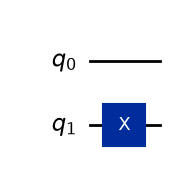

In [9]:
display(deutsch_function(4).draw('mpl'))

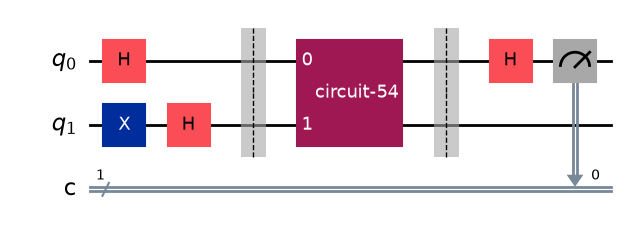

In [12]:
Deutsch = QuantumCircuit(2, 1)

Deutsch.h(0)
Deutsch.x(1)
Deutsch.h(1)
Deutsch.barrier()

Deutsch.append(deutsch_function(4), [0, 1])
Deutsch.barrier()

Deutsch.h(0)
Deutsch.measure(0, 0)

display(Deutsch.draw('mpl'))


In [13]:
def compile_circuit(function: QuantumCircuit):
    # Compiles a circuit for use in Deutsch's algorithm.

    n = function.num_qubits - 1
    qc = QuantumCircuit(n + 1, n)

    qc.x(n)
    qc.h(range(n + 1))

    qc.barrier()
    qc.compose(function, inplace=True)
    qc.barrier()

    qc.h(range(n))
    qc.measure(range(n), range(n))

    return qc

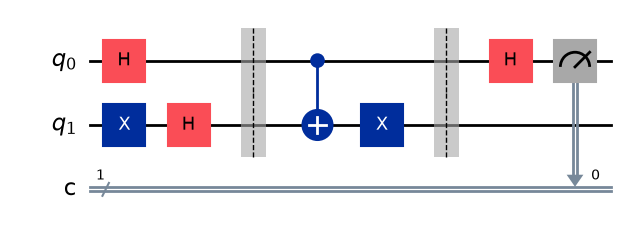

In [14]:
display(compile_circuit(deutsch_function(3)).draw(output="mpl"))

In [18]:
def Deutsch_algorithm(function: QuantumCircuit):
    qc = compile_circuit(function)

    result = AerSimulator().run(qc, shots=1, memory=True).result()
    measurement = result.get_memory()[0]
    if measurement[0] == "0":
        return "Constant function"
    return "Balanced function"

In [20]:
f = deutsch_function(3)
display(Deutsch_algorithm(f))

'Balanced function'